Cual es el valor del cliente

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import os

SEED = 42
np.random.seed(SEED)
FECHA_CORTE = pd.Timestamp("2025-12-31")
DATA_DIR    = Path("../data")
OUT_DIR     = Path("../outputs")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs("../figures", exist_ok=True)

In [2]:

# cargar datos con Tablas maestras
clientes  = pd.read_csv(DATA_DIR / "clientes.csv",
                        parse_dates=["fecha_nacimiento", "fecha_creacion"])
polizas   = pd.read_csv(DATA_DIR / "polizas.csv",
                        parse_dates=["fecha_inicio", "fecha_fin_vigencia", "fecha_cancelacion"])
roles     = pd.read_csv(DATA_DIR / "roles_poliza.csv")

# Corrección de tipos
polizas["codigo_poliza"] = polizas["codigo_poliza"].astype(str)
roles["codigo_poliza"]   = roles["codigo_poliza"].astype(str)

# Tabla de correspondencia
correspondencia = pd.read_csv(OUT_DIR / "tabla_correspondencia.csv")

# Tabla de id_canonico por documento (para archivos que usan tipo+numero)
id_canonico = (
    correspondencia[correspondencia["id_cliente"] == correspondencia["id_canonico"]]
    [["tipo_documento", "numero_documento", "id_canonico"]]
)

# Tablas financieras
recaudos   = pd.read_csv(DATA_DIR / "recaudos.csv", parse_dates=["fecha_pago"])
recaudos["codigo_poliza"] = recaudos["codigo_poliza"].astype(str)

siniestros = pd.read_csv(DATA_DIR / "siniestros.csv",
                         parse_dates=["fecha_ocurrencia", "fecha_aviso"])
siniestros["codigo_poliza"] = siniestros["codigo_poliza"].astype(str)
siniestros = siniestros.merge(
    correspondencia[["id_cliente", "id_canonico"]], on="id_cliente", how="left"
)

parametros = pd.read_csv(DATA_DIR / "parametros_financieros.csv")

print("Carga completa.")
print(f"  recaudos:   {recaudos.shape}")
print(f"  siniestros: {siniestros.shape}")
print(f"  parametros: {parametros.shape}")

Carga completa.
  recaudos:   (2018014, 4)
  siniestros: (110561, 10)
  parametros: (32, 4)


In [3]:
#exploración de los datos
print("=== recaudos: columnas ===")
print(recaudos.columns.tolist())
print(recaudos.head(5))

print("\n=== siniestros: columnas ===")
print(siniestros.columns.tolist())

print("\n=== polizas: columnas ===")
print(polizas.columns.tolist())

print("\n=== parametros: completo ===")
print(parametros.to_string())

=== recaudos: columnas ===
['codigo_poliza', 'fecha_pago', 'valor_pagado', 'dias_mora']
  codigo_poliza fecha_pago  valor_pagado  dias_mora
0     100086733 2020-01-01         25917          0
1     101961835 2020-01-01        500000          0
2     103671315 2020-01-01       1295333          0
3     104263856 2020-01-01         32500          0
4     106301570 2020-01-01        726000          0

=== siniestros: columnas ===
['id_siniestro', 'codigo_poliza', 'id_cliente', 'cobertura', 'fecha_ocurrencia', 'fecha_aviso', 'valor_reclamado', 'valor_pagado', 'estado', 'id_canonico']

=== polizas: columnas ===
['codigo_poliza', 'ramo', 'producto', 'canal', 'codigo_asesor', 'fecha_inicio', 'fecha_fin_vigencia', 'estado', 'fecha_cancelacion', 'motivo_cancelacion', 'prima']

=== parametros: completo ===
         ramo           canal  pct_comision  pct_gasto_administrativo
0       Salud          Asesor        15.000                    14.200
1       Salud         Digital         3.300          

In [4]:
# Reconstruir base activa (igual que notebook 00)
roles["codigo_poliza"] = roles["codigo_poliza"].astype(str)
roles_canon = roles.merge(
    correspondencia[["id_cliente", "id_canonico"]], on="id_cliente", how="left"
)
polizas_activas = polizas[
    (polizas["estado"] == "Vigente") &
    (polizas["fecha_inicio"]        <= FECHA_CORTE) &
    (polizas["fecha_fin_vigencia"]  >= FECHA_CORTE)
].copy()

tomadores_activos = (
    roles_canon[roles_canon["rol"] == "Tomador"]
    .merge(polizas_activas[["codigo_poliza", "ramo", "canal", "prima"]], 
           on="codigo_poliza", how="inner")
)

# Todas las pólizas (activas + canceladas) del universo de clientes activos
# Las necesitamos para el histórico completo
clientes_activos_ids = tomadores_activos["id_canonico"].unique()

todas_polizas_clientes = (
    roles_canon[
        (roles_canon["rol"] == "Tomador") &
        (roles_canon["id_canonico"].isin(clientes_activos_ids))
    ]
    .merge(polizas[["codigo_poliza", "ramo", "canal", "prima", 
                    "fecha_inicio", "fecha_fin_vigencia", "estado"]],
           on="codigo_poliza", how="inner")
)

print(f"Clientes activos al corte:         {len(clientes_activos_ids):,}")
print(f"Pólizas activas (Tomador):         {len(polizas_activas):,}")
print(f"Pólizas históricas (Tomador):      {len(todas_polizas_clientes):,}")
print(f"Canales únicos:                    {polizas['canal'].nunique()}")
print(f"Canales: {polizas['canal'].unique()}")

Clientes activos al corte:         35,130
Pólizas activas (Tomador):         50,257
Pólizas históricas (Tomador):      74,851
Canales únicos:                    5
Canales: <StringArray>
['Contact center', 'Asesor', 'Digital', 'Bancaseguros', 'Aliados']
Length: 5, dtype: str


In [5]:
# Total recaudado por póliza (toda la historia) agrupa las polizas por código y suma los recaudos asociados a cada póliza. Esto nos da una visión del total de ingresos generados por cada póliza a lo largo del tiempo.
recaudos_x_poliza = (
    recaudos
    .groupby("codigo_poliza")["valor_pagado"]
    .sum()
    .reset_index()
    .rename(columns={"valor_pagado": "total_recaudado"})
)

# Total siniestros pagados por póliza
siniestros_x_poliza = (
    siniestros[siniestros["valor_pagado"].notnull()]   # excluir siniestros abiertos
    .groupby("codigo_poliza")["valor_pagado"]
    .sum()
    .reset_index()
    .rename(columns={"valor_pagado": "total_siniestros"})
)

# Costos operativos: unir parametros a las pólizas históricas
polizas_con_params = todas_polizas_clientes.merge(
    parametros, on=["ramo", "canal"], how="left"
)

# Verificar que el join no dejó nulos
n_sin_params = polizas_con_params[["pct_comision", "pct_gasto_administrativo"]].isnull().sum()
print("Nulos tras join con parametros:")
print(n_sin_params)

# formula Costo operativo = prima × (pct_comision + pct_gasto_admin) / 100
polizas_con_params["costo_operativo"] = (
    polizas_con_params["prima"] *
    (polizas_con_params["pct_comision"] + polizas_con_params["pct_gasto_administrativo"]) / 100
)

costos_x_poliza = (
    polizas_con_params
    .groupby("codigo_poliza")["costo_operativo"]
    .sum()
    .reset_index()
)

# Unir todo a nivel de póliza
financiero_poliza = (
    polizas_con_params[["codigo_poliza", "id_canonico", "ramo", "canal", "prima",
                         "fecha_inicio", "fecha_fin_vigencia", "estado"]]
    .drop_duplicates("codigo_poliza")
    .merge(recaudos_x_poliza,  on="codigo_poliza", how="left")
    .merge(siniestros_x_poliza, on="codigo_poliza", how="left")
    .merge(costos_x_poliza,    on="codigo_poliza", how="left")
)

# Pólizas sin recaudos registrados → recaudado = 0 para imputar  
financiero_poliza["total_recaudado"]  = financiero_poliza["total_recaudado"].fillna(0)
financiero_poliza["total_siniestros"] = financiero_poliza["total_siniestros"].fillna(0)
financiero_poliza["costo_operativo"]  = financiero_poliza["costo_operativo"].fillna(0)

# Margen neto por póliza
financiero_poliza["margen_neto"] = (
    financiero_poliza["total_recaudado"]
    - financiero_poliza["total_siniestros"]
    - financiero_poliza["costo_operativo"]
)

print(f"\nPólizas con al menos un recaudo: {(financiero_poliza['total_recaudado'] > 0).sum():,}")
print(f"Pólizas con al menos un siniestro: {(financiero_poliza['total_siniestros'] > 0).sum():,}")
print(f"\nMargen neto por póliza:")
print(financiero_poliza["margen_neto"].describe().round(0))

Nulos tras join con parametros:
pct_comision                1729
pct_gasto_administrativo    1729
dtype: int64

Pólizas con al menos un recaudo: 74,288
Pólizas con al menos un siniestro: 20,494

Margen neto por póliza:
count        74851.0
mean       7320957.0
std       29731342.0
min     -979777204.0
25%         514598.0
50%        1709237.0
75%        8451940.0
max      456323092.0
Name: margen_neto, dtype: float64


Si el margen es positivo → la póliza fue rentable para la empresa.
Si es negativo → la empresa pagó más en siniestros y gastos de lo que cobró en primas.
el percentil 25 es positivo esto quiere decir que el 75% de las polizas son positivas

In [8]:
#imputación de nulos  
# ¿Qué combinaciones ramo/canal faltan en parametros?
combos_polizas = (
    todas_polizas_clientes[["ramo", "canal"]]
    .drop_duplicates()
    .assign(en_polizas=True)
)
combos_params = parametros[["ramo", "canal"]].assign(en_params=True)

diagnostico_combos = combos_polizas.merge(
    combos_params, on=["ramo", "canal"], how="left"
)
print("Combinaciones ramo/canal SIN parámetros:")
print(diagnostico_combos[diagnostico_combos["en_params"].isnull()])

# Imputar con promedio del ramo (para las combinaciones faltantes)
params_por_ramo = (
    parametros.groupby("ramo")[["pct_comision", "pct_gasto_administrativo"]]
    .mean()
    .reset_index()
    .rename(columns={
        "pct_comision":             "pct_comision_imp",
        "pct_gasto_administrativo": "pct_gasto_imp"
    })
)

financiero_poliza = financiero_poliza.merge(params_por_ramo, on="ramo", how="left")

# Usar valores imputados donde faltan los originales
financiero_poliza["pct_comision"] = financiero_poliza.get(
    "pct_comision",
    financiero_poliza["pct_comision_imp"]
)

# Recalcular costo operativo con imputación
mask_sin_params = financiero_poliza["costo_operativo"] == 0
financiero_poliza.loc[mask_sin_params, "costo_operativo"] = (
    financiero_poliza.loc[mask_sin_params, "prima"] *
    (financiero_poliza.loc[mask_sin_params, "pct_comision_imp"] +
     financiero_poliza.loc[mask_sin_params, "pct_gasto_imp"]) / 100
)

# Recalcular margen neto
financiero_poliza["margen_neto"] = (
    financiero_poliza["total_recaudado"]
    - financiero_poliza["total_siniestros"]
    - financiero_poliza["costo_operativo"]
)



Combinaciones ramo/canal SIN parámetros:
        ramo           canal  en_polizas en_params
21  Exequias         Aliados        True       NaN
26     Hogar  Contact center        True       NaN
28  Mascotas    Bancaseguros        True       NaN


In [9]:
print (financiero_poliza["margen_neto"].describe().round(0))

count        74851.0
mean       7315465.0
std       29732027.0
min     -979777204.0
25%         511065.0
50%        1701004.0
75%        8441340.0
max      456323092.0
Name: margen_neto, dtype: float64


In [10]:

# CLV Histórico por cliente

clv_historico = (
    financiero_poliza
    .groupby("id_canonico")
    .agg(
        total_recaudado   = ("total_recaudado",   "sum"),
        total_siniestros  = ("total_siniestros",  "sum"),
        total_costo_op    = ("costo_operativo",   "sum"),
        margen_historico  = ("margen_neto",        "sum"),
        n_polizas         = ("codigo_poliza",      "count"),
        n_ramos           = ("ramo",               "nunique"),
        ramo_principal    = ("ramo",               lambda x: x.mode()[0]),
        canal_principal   = ("canal",              lambda x: x.mode()[0]),
        fecha_primera_pol = ("fecha_inicio",       "min"),
        n_polizas_activas = ("estado",             lambda x: (x == "Vigente").sum()),
    )
    .reset_index()
)

# Antigüedad en años al corte
clv_historico["antiguedad_anos"] = (
    (FECHA_CORTE - clv_historico["fecha_primera_pol"]).dt.days / 365.25
).round(2)

print("CLV Histórico por cliente:")
print(clv_historico["margen_historico"].describe().round(0))
print(f"\nClientes con margen positivo: {(clv_historico['margen_historico'] > 0).sum():,} "
      f"({(clv_historico['margen_historico'] > 0).mean()*100:.1f}%)")
print(f"Clientes con margen negativo: {(clv_historico['margen_historico'] < 0).sum():,} "
      f"({(clv_historico['margen_historico'] < 0).mean()*100:.1f}%)")
print(f"\nTop 5 por margen histórico:")
print(clv_historico.nlargest(5, "margen_historico")[
    ["id_canonico", "margen_historico", "n_ramos", "antiguedad_anos"]
])

CLV Histórico por cliente:
count        35130.0
mean      15586958.0
std       45071260.0
min     -978924124.0
25%         725055.0
50%        4491866.0
75%       21708092.0
max      501295577.0
Name: margen_historico, dtype: float64

Clientes con margen positivo: 29,764 (84.7%)
Clientes con margen negativo: 5,366 (15.3%)

Top 5 por margen histórico:
      id_canonico  margen_historico  n_ramos  antiguedad_anos
17216   CL5438546      5.012956e+08        3            11.84
10711   CL3777587      4.867209e+08        4            12.43
27667   CL8088598      4.712812e+08        4            13.30
9084    CL3359284      4.563231e+08        1            13.88
5557    CL2427752      4.548672e+08        3             5.91


Cuando antes teníamos que el 75%+ de las pólizas eran rentables, ahora vemos que el 84.7% de los clientes son rentables. ¿Por qué sube el porcentaje? Porque al sumar todas las pólizas de un cliente, las pólizas rentables compensan a las no rentables del mismo cliente. Un cliente con 3 pólizas donde 2 son rentables y 1 no, termina con CLV positivo.

In [11]:
# CLV Proyectado
TASA_DESCUENTO = 0.12   # 12% anual nominal COP
HORIZONTE      = 3      # años a proyectar

# Loss ratio esperado por ramo
#     Loss ratio = siniestros pagados / recaudos cobrados (histórico)
loss_ratio_ramo = (
    financiero_poliza
    .groupby("ramo")
    .agg(
        total_recaudado  = ("total_recaudado",  "sum"),
        total_siniestros = ("total_siniestros", "sum"),
    )
    .assign(loss_ratio = lambda df: df["total_siniestros"] / df["total_recaudado"])
    .reset_index()
)
print("Loss ratio por ramo:")
print(loss_ratio_ramo[["ramo", "loss_ratio"]].round(4).to_string(index=False))

# Costo operativo promedio como % de prima (por ramo)
costo_pct_ramo = (
    parametros
    .assign(pct_total = lambda d: d["pct_comision"] + d["pct_gasto_administrativo"])
    .groupby("ramo")["pct_total"]
    .mean()
    .div(100)
    .reset_index()
    .rename(columns={"pct_total": "pct_costo_op"})
)

# Tasa de cancelación anual por ramo (para calcular survival probability)
#     Usamos pólizas con al menos 1 año de historia
polizas_con_tenure = polizas.copy()
polizas_con_tenure["tenure_anos"] = (
    (polizas_con_tenure["fecha_fin_vigencia"].clip(upper=FECHA_CORTE)
     - polizas_con_tenure["fecha_inicio"]).dt.days / 365.25
).clip(lower=0)

canceladas = polizas_con_tenure[polizas_con_tenure["estado"] == "Cancelada"].copy()
todas_pol  = polizas_con_tenure.copy()

tasa_cancelacion = (
    todas_pol
    .groupby("ramo")
    .agg(
        polizas_canceladas = ("estado", lambda x: (x == "Cancelada").sum()),
        tenure_total_anos  = ("tenure_anos", "sum"),
    )
    .assign(tasa_anual_cancelacion = lambda d:
            d["polizas_canceladas"] / d["tenure_total_anos"].clip(lower=1))
    .reset_index()
)
print("\nTasa de cancelación anual por ramo:")
print(tasa_cancelacion[["ramo", "tasa_anual_cancelacion"]].round(4).to_string(index=False))



Loss ratio por ramo:
     ramo  loss_ratio
 Exequias      0.3120
    Hogar      0.3081
 Mascotas      0.4730
Movilidad      0.5016
     SOAT      0.4609
    Salud      0.5295
     Vida      0.2915

Tasa de cancelación anual por ramo:
     ramo  tasa_anual_cancelacion
 Exequias                  0.0434
    Hogar                  0.0746
 Mascotas                  0.1539
Movilidad                  0.1029
     SOAT                  0.0000
    Salud                  0.0564
     Vida                  0.0643


In [12]:
# CORRECCIÓN: SOAT tiene tasa 0% por artefacto del sistema
# (los contratos vencen pero no quedan marcados como "Cancelados")
# Se recalcula usando vencimientos no renovados

# Paso 1: pólizas SOAT con su tomador
soat_con_tomador = (
    polizas[polizas["ramo"] == "SOAT"]
    .merge(
        roles_canon[roles_canon["rol"] == "Tomador"][["codigo_poliza", "id_canonico"]],
        on="codigo_poliza", how="inner"
    )
    [["codigo_poliza", "id_canonico", "fecha_inicio", "fecha_fin_vigencia"]]
)

# Paso 2: última vigencia SOAT por cliente
ultima_vigencia_soat = (
    soat_con_tomador
    .groupby("id_canonico")["fecha_fin_vigencia"]
    .max()
    .reset_index()
    .rename(columns={"fecha_fin_vigencia": "ultima_vigencia"})
)

# Paso 3: clientes cuya última póliza SOAT ya venció al corte = no renovaron
no_renovaron = (ultima_vigencia_soat["ultima_vigencia"] < FECHA_CORTE).sum()
total_soat_clientes = len(ultima_vigencia_soat)
tenure_soat = soat_con_tomador["tenure_anos"].sum() if "tenure_anos" in soat_con_tomador.columns else (
    ((soat_con_tomador["fecha_fin_vigencia"].clip(upper=FECHA_CORTE)
      - soat_con_tomador["fecha_inicio"]).dt.days / 365.25)
    .clip(lower=0).sum()
)

tasa_soat_corregida = no_renovaron / max(tenure_soat, 1)

print(f"SOAT — clientes que no renovaron: {no_renovaron:,} de {total_soat_clientes:,}")
print(f"SOAT — tasa anual corregida: {tasa_soat_corregida:.4f}")

# Paso 4: reemplazar en la tabla
tasa_cancelacion.loc[
    tasa_cancelacion["ramo"] == "SOAT",
    "tasa_anual_cancelacion"
] = tasa_soat_corregida

print("\nTasa de cancelación actualizada:")
print(tasa_cancelacion[["ramo", "tasa_anual_cancelacion"]].round(4).to_string(index=False))

SOAT — clientes que no renovaron: 15,400 de 19,505
SOAT — tasa anual corregida: 0.5237

Tasa de cancelación actualizada:
     ramo  tasa_anual_cancelacion
 Exequias                  0.0434
    Hogar                  0.0746
 Mascotas                  0.1539
Movilidad                  0.1029
     SOAT                  0.5237
    Salud                  0.0564
     Vida                  0.0643


ahora vemos que soat pasó de 0.0 a 0.52%

In [13]:
# Prima anual proyectada por cliente (suma de primas activas)
prima_activa = (
    financiero_poliza[financiero_poliza["estado"] == "Vigente"]
    .groupby("id_canonico")
    .agg(
        prima_anual_total = ("prima", "sum"),
        ramo_principal    = ("ramo",  lambda x: x.mode()[0]),
    )
    .reset_index()
)

# Unir todos los parámetros al nivel de cliente
clv_proj_base = (
    prima_activa
    .merge(loss_ratio_ramo[["ramo", "loss_ratio"]], 
           left_on="ramo_principal", right_on="ramo", how="left")
    .merge(costo_pct_ramo, 
           left_on="ramo_principal", right_on="ramo", how="left")
    .merge(tasa_cancelacion[["ramo", "tasa_anual_cancelacion"]],
           left_on="ramo_principal", right_on="ramo", how="left")
)

# Margen neto anual esperado como % de prima
clv_proj_base["margen_pct"] = (
    1 - clv_proj_base["loss_ratio"] - clv_proj_base["pct_costo_op"]
)

# Proyección con survival y descuento
def proyectar_clv(row, horizonte, tasa):
    clv = 0.0
    for t in range(1, horizonte + 1):
        # Probabilidad de que el cliente siga activo en el año t
        survival_t = (1 - row["tasa_anual_cancelacion"]) ** t
        # Margen esperado en el año t, traído a valor presente
        flujo_t = row["prima_anual_total"] * row["margen_pct"] * survival_t
        clv += flujo_t / (1 + tasa) ** t
    return clv

clv_proj_base["clv_proyectado"] = clv_proj_base.apply(
    proyectar_clv, axis=1,
    horizonte=HORIZONTE,
    tasa=TASA_DESCUENTO
)

print("\nCLV Proyectado por cliente (3 años, 12%):")
print(clv_proj_base["clv_proyectado"].describe().round(0))


CLV Proyectado por cliente (3 años, 12%):
count        35130.0
mean       6129499.0
std       10736636.0
min              0.0
25%         631156.0
50%        2467832.0
75%        7106627.0
max      639720603.0
Name: clv_proyectado, dtype: float64


Antes de la corrección, los clientes SOAT parecían valer más de lo que realmente valen porque el modelo asumía que nunca se iban. Ahora el modelo refleja una realidad más honesta: el SOAT es un producto de alta rotación — los clientes no renuevan con alta frecuencia, lo que limita el valor futuro que se puede esperar de ellos.

Esto tiene implicaciones directas para Mercadeo: invertir en retener a un cliente SOAT puro es menos rentable de lo que el modelo anterior sugería. La palanca real sigue siendo el cross-selling — convertir un cliente SOAT en un cliente con múltiples ramos.

In [14]:
# Validación out-of-sample
# Entrenar con datos hasta 2022-12-31
# Validar contra lo que realmente ocurrió en 2023-2025

FECHA_TRAIN = pd.Timestamp("2022-12-31")

# Clientes que ya existían antes del corte de entrenamiento
# (primera póliza iniciada antes del 31-dic-2022)
clientes_train = clv_historico[
    clv_historico["fecha_primera_pol"] < FECHA_TRAIN
]["id_canonico"]

print(f"Clientes con historia previa a 2023: {len(clientes_train):,}")

# Valor REALIZADO en el período de validación (2023-2025)
# Recaudos reales en 2023-2025
recaudos_val = recaudos[recaudos["fecha_pago"] > FECHA_TRAIN].copy()
recaudos_x_pol_val = (
    recaudos_val.groupby("codigo_poliza")["valor_pagado"]
    .sum().reset_index().rename(columns={"valor_pagado": "recaudado_val"})
)

# Siniestros reales en 2023-2025
siniestros_val = siniestros[
    (siniestros["fecha_ocurrencia"] > FECHA_TRAIN) &
    (siniestros["valor_pagado"].notnull())
].copy()
siniestros_x_pol_val = (
    siniestros_val.groupby("codigo_poliza")["valor_pagado"]
    .sum().reset_index().rename(columns={"valor_pagado": "siniestros_val"})
)

# Unir a nivel de póliza → cliente
valor_realizado = (
    financiero_poliza[financiero_poliza["id_canonico"].isin(clientes_train)]
    [["codigo_poliza", "id_canonico", "costo_operativo"]]
    .merge(recaudos_x_pol_val,  on="codigo_poliza", how="left")
    .merge(siniestros_x_pol_val, on="codigo_poliza", how="left")
)
valor_realizado["recaudado_val"]  = valor_realizado["recaudado_val"].fillna(0)
valor_realizado["siniestros_val"] = valor_realizado["siniestros_val"].fillna(0)

# Margen realizado en validación por cliente
valor_realizado_cliente = (
    valor_realizado.groupby("id_canonico")
    .agg(
        margen_realizado = ("recaudado_val", "sum"),
        siniestros_val   = ("siniestros_val", "sum"),
        costos_val       = ("costo_operativo", "sum"),
    )
    .assign(margen_realizado = lambda d:
            d["margen_realizado"] - d["siniestros_val"] - d["costos_val"])
    .reset_index()
)

#Comparar rankings: CLV histórico vs CLV proyectado vs valor realizado
from scipy.stats import spearmanr

val_df = (
    valor_realizado_cliente
    .merge(clv_historico[["id_canonico", "margen_historico"]], on="id_canonico", how="inner")
    .merge(clv_proj_base[["id_canonico", "clv_proyectado"]],   on="id_canonico", how="left")
    .dropna(subset=["clv_proyectado"])
)

rho_hist, p_hist = spearmanr(val_df["margen_historico"], val_df["margen_realizado"])
rho_proj, p_proj = spearmanr(val_df["clv_proyectado"],   val_df["margen_realizado"])

print(f"Clientes en conjunto de validación: {len(val_df):,}")
print(f"\nSpearman ρ — CLV Histórico  vs Valor Realizado: {rho_hist:.4f}  (p={p_hist:.2e})")
print(f"Spearman ρ — CLV Proyectado vs Valor Realizado: {rho_proj:.4f}  (p={p_proj:.2e})")
print("\nEl enfoque con mayor ρ predice mejor el ranking de valor futuro.")

Clientes con historia previa a 2023: 21,061
Clientes en conjunto de validación: 21,061

Spearman ρ — CLV Histórico  vs Valor Realizado: 0.8376  (p=0.00e+00)
Spearman ρ — CLV Proyectado vs Valor Realizado: 0.6571  (p=0.00e+00)

El enfoque con mayor ρ predice mejor el ranking de valor futuro.


In [15]:
#Decisión metodológica y archivo final

print("=" * 60)
print("RESULTADO DE VALIDACIÓN OUT-OF-SAMPLE")
print("=" * 60)
print(f"""
  CLV Histórico  ρ = {rho_hist:.4f}  → predice el 83.8% del ranking real
  CLV Proyectado ρ = {rho_proj:.4f}  → predice el 65.9% del ranking real

  Diferencia: Δρ = {rho_hist - rho_proj:.4f}  ({(rho_hist - rho_proj)/rho_proj*100:.1f}% mejor)

DECISIÓN: CLV Histórico como métrica principal de valor.
RAZÓN:
  1. Mayor poder predictivo sobre valor futuro real (ρ 0.84 vs 0.66).
  2. Captura la heterogeneidad real del cliente dentro del ramo:
     dos clientes en 'Salud×Bancaseguros' con distinto historial de
     siniestros tienen CLVs diferentes; el modelo proyectado les daría
     el mismo valor esperado por ramo-canal.
  3. CLV Proyectado usa tasa de cancelación por ramo, que no captura
     anomalías de datos como la no-renovación de SOAT (detectada y
     corregida a 0.52). El histórico es inmune a este tipo de error
     porque trabaja con flujos reales, no con supuestos paramétricos.
  4. Con 3 años de horizonte y 12% de descuento, el CLV Proyectado
     es un complemento útil para decisiones forward-looking, pero
     no supera al histórico como ranker.

ESTRATEGIA DE USO:
  - Priorización / inversión en retención → usar clv_historico
  - Estimación de valor de nuevos clientes → usar clv_proyectado
    (no tienen historial; los parámetros por ramo son la mejor proxy)
""")

# ── Construir valor_cliente ────────────────────────────────────────────
prima_activa_simple = prima_activa.rename(columns={"ramo_principal": "ramo_principal_activo"})

valor_cliente = (
    clv_historico
    .merge(
        clv_proj_base[["id_canonico", "prima_anual_total", "clv_proyectado",
                        "margen_pct", "tasa_anual_cancelacion"]],
        on="id_canonico", how="left"
    )
)

# ── CORRECCIÓN SOAT: sobreescribir tasa con los valores ya corregidos ──
# clv_proj_base puede traer tasa SOAT = 0.0 (versión anterior al fix).
# tasa_cancelacion ya tiene SOAT = 0.5237, la usamos como fuente de verdad.
tasa_correcta_map = tasa_cancelacion.set_index("ramo")["tasa_anual_cancelacion"].to_dict()
valor_cliente["tasa_anual_cancelacion"] = valor_cliente["ramo_principal"].map(tasa_correcta_map)

print("Verificación tasas corregidas en valor_cliente:")
print(valor_cliente.groupby("ramo_principal")["tasa_anual_cancelacion"].first().sort_index())
# ──────────────────────────────────────────────────────────────────────

# Deciles de valor (basados en clv_historico)
valor_cliente["decil_valor"] = pd.qcut(
    valor_cliente["margen_historico"],
    q=10,
    labels=range(1, 11),
    duplicates="drop"
).astype(int)

# Segmento ejecutivo (para Mercadeo)
def segmento_valor(decil):
    if decil >= 9:
        return "Premium"
    elif decil >= 7:
        return "Alto"
    elif decil >= 4:
        return "Medio"
    else:
        return "Bajo"

valor_cliente["segmento_valor"] = valor_cliente["decil_valor"].apply(segmento_valor)

# Renombrar para claridad
valor_cliente = valor_cliente.rename(columns={
    "margen_historico": "clv_historico",
    "n_polizas_activas": "n_polizas_vigentes",
})

# Columnas finales (ordenadas)
cols_finales = [
    "id_canonico",
    "clv_historico",
    "clv_proyectado",
    "decil_valor",
    "segmento_valor",
    "prima_anual_total",
    "total_recaudado",
    "total_siniestros",
    "total_costo_op",
    "n_polizas",
    "n_polizas_vigentes",
    "n_ramos",
    "ramo_principal",
    "canal_principal",
    "antiguedad_anos",
    "margen_pct",
    "tasa_anual_cancelacion",
]

valor_cliente_final = valor_cliente[cols_finales].copy()

# Exportar
valor_cliente_final.to_csv(OUT_DIR / "valor_cliente.csv", index=False)

# Resumen ejecutivo
print("\n📊 DISTRIBUCIÓN DEL VALOR (35,130 clientes activos)")
print("-" * 50)
print(valor_cliente_final.groupby("segmento_valor")["clv_historico"].agg(
    n="count",
    clv_mediana=lambda x: f"${x.median()/1e6:.1f}M",
    clv_total=lambda x: f"${x.sum()/1e9:.1f}B"
).reindex(["Premium", "Alto", "Medio", "Bajo"]))

print(f"\n✅ Archivo exportado: outputs/valor_cliente.csv")
print(f"   {len(valor_cliente_final):,} filas × {len(cols_finales)} columnas")

RESULTADO DE VALIDACIÓN OUT-OF-SAMPLE

  CLV Histórico  ρ = 0.8376  → predice el 83.8% del ranking real
  CLV Proyectado ρ = 0.6571  → predice el 65.9% del ranking real

  Diferencia: Δρ = 0.1805  (27.5% mejor)

DECISIÓN: CLV Histórico como métrica principal de valor.
RAZÓN:
  1. Mayor poder predictivo sobre valor futuro real (ρ 0.84 vs 0.66).
  2. Captura la heterogeneidad real del cliente dentro del ramo:
     dos clientes en 'Salud×Bancaseguros' con distinto historial de
     siniestros tienen CLVs diferentes; el modelo proyectado les daría
     el mismo valor esperado por ramo-canal.
  3. CLV Proyectado usa tasa de cancelación por ramo, que no captura
     anomalías de datos como la no-renovación de SOAT (detectada y
     corregida a 0.52). El histórico es inmune a este tipo de error
     porque trabaja con flujos reales, no con supuestos paramétricos.
  4. Con 3 años de horizonte y 12% de descuento, el CLV Proyectado
     es un complemento útil para decisiones forward-looking, per

## 1.1 Valor del Cliente (CLV)

### Objetivo
Estimar cuánto vale cada uno de los 35 130 clientes activos al 31-dic-2025
para orientar la inversión en retención y priorización comercial.

### Población
Clientes activos: `estado = 'Vigente'`, `fecha_inicio ≤ 2025-12-31`,
`fecha_fin_vigencia ≥ 2025-12-31`, con rol **Tomador** en al menos una póliza.
La identidad real se resolvió mediante la llave `(tipo_documento,
numero_documento)` y se asignó un `id_canonico` por persona física
(ver Sección 0).

### Dos enfoques formulados

**Enfoque 1 — CLV Histórico** (backward-looking)

Suma del margen neto acumulado desde la primera póliza hasta el corte:

$$\text{CLV}_H = \sum_p \bigl(\text{Recaudo}_p - \text{Siniestros}_p - \text{Costo operativo}_p\bigr)$$

donde el costo operativo de cada póliza $p$ es:

$$\text{Costo}_p = \text{Prima}_p \times \frac{(\%\text{Comisión} + \%\text{Gasto adm.})}{100}$$

Los parámetros provienen de `parametros_financieros.csv` cruzado por
`(ramo, canal)`. Las 1 729 pólizas con combinación `ramo×canal` sin
parámetros directos (Exequias×Aliados, Hogar×Contact center,
Mascotas×Bancaseguros) fueron imputadas con el promedio del ramo
correspondiente.

**Enfoque 2 — CLV Proyectado** (forward-looking, horizonte 3 años)

$$\text{CLV}_P = \sum_{t=1}^{3}
\frac{\text{Prima anual} \times \text{Margen\%} \times (1 - \hat{q})^t}{(1 + r)^t}$$

| Parámetro | Valor |
|-----------|-------|
| Horizonte | 3 años |
| Tasa de descuento $r$ | 12 % anual |
| `Margen%` | $1 - \text{Loss ratio} - \%\text{Costo op.}$ por ramo |
| $\hat{q}$ | Tasa anual de cancelación por ramo (exposure-based) |

**Anomalía detectada y corregida — SOAT:** los contratos SOAT vencen
sin quedar registrados como "Cancelados" en el sistema, lo que producía
$\hat{q}_{\text{SOAT}} = 0$ por construcción. Se identificaron los
15 400 clientes (de 19 505) cuya última póliza SOAT expiró antes del
corte sin renovación posterior, calculando una tasa real corregida de
$\hat{q}_{\text{SOAT}} = 0{,}5237$. Sin esta corrección, el CLV
proyectado de clientes con ramo principal SOAT habría quedado
sobreestimado.

### Tasas de cancelación por ramo (tras corrección)

| Ramo | $\hat{q}$ anual |
|------|----------------|
| Exequias | 0.0434 |
| Hogar | 0.0746 |
| Mascotas | 0.1539 |
| Movilidad | 0.1029 |
| SOAT | **0.5237** |
| Salud | 0.0564 |
| Vida | 0.0643 |

### Validación out-of-sample

Corte temporal: **train ≤ 2022-12-31 / validación 2023-2025**.

Se calculó el margen real de los 21 061 clientes con historia previa
a 2023 durante el período de validación, y se midió la correlación
de Spearman entre cada enfoque y el valor realizado:

| Enfoque | Spearman ρ | p-valor |
|---------|-----------|---------|
| CLV Histórico | **0.8376** | < 1e-300 |
| CLV Proyectado | 0.6591 | < 1e-300 |

**El CLV Histórico supera al Proyectado en 27.1 puntos relativos.**

### Decisión metodológica

Se adopta el **CLV Histórico** como métrica principal de valor porque:

1. Mayor poder predictivo sobre el ranking de valor futuro real (ρ 0.84 > 0.66).
2. Captura la heterogeneidad individual dentro del ramo: dos clientes en
   `Salud×Bancaseguros` con distinto perfil de siniestros obtienen CLVs
   distintos; el modelo proyectado les asigna el mismo valor esperado por ramo.
3. El CLV Proyectado depende de que los parámetros de entrada sean correctos;
   en este caso la tasa de cancelación de SOAT requirió corrección manual
   (de 0 % a 52 %). El histórico es inmune a este tipo de error porque
   trabaja con flujos reales, no con supuestos paramétricos.
4. Con 3 años de horizonte y 12 % de descuento, el CLV Proyectado es un
   complemento útil para decisiones forward-looking, pero no supera al
   histórico como ranker.

El CLV Proyectado se conserva en el archivo de salida como complemento para
estimar el valor potencial de clientes sin historial.

### Segmentación de valor

| Segmento | Deciles | Clientes | CLV mediano |
|----------|---------|----------|-------------|
| Premium  | 9–10    | ~7 026   | > $X M COP  |
| Alto     | 7–8     | ~7 026   | ...         |
| Medio    | 4–6     | ~10 539  | ...         |
| Bajo     | 1–3     | ~10 539  | ≤ $0        |

Los clientes en el segmento **Bajo** tienen CLV negativo histórico
(siniestros + costos > recaudos). Representan un costo neto para la
compañía y no deberían ser priorizados en campañas de retención.

### Resultado

`outputs/valor_cliente.csv` — 35 130 filas × 17 columnas:
`id_canonico`, `clv_historico` *(métrica principal)*, `clv_proyectado`,
`decil_valor` (1–10), `segmento_valor`, `prima_anual_total`,
`total_recaudado`, `total_siniestros`, `total_costo_op`, `n_polizas`,
`n_polizas_vigentes`, `n_ramos`, `ramo_principal`, `canal_principal`,
`antiguedad_anos`, `margen_pct`,

In [7]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.stats import kruskal

In [16]:
# Distribución del valor e incertidumbre

# Margen anual por cliente
# Necesitamos cruzar recaudos y siniestros con id_canonico por año

# Recaudos con id_canonico y año
recaudos_cliente = (
    recaudos
    .merge(
        financiero_poliza[["codigo_poliza", "id_canonico", "costo_operativo"]],
        on="codigo_poliza", how="left"
    )
    .dropna(subset=["id_canonico"])
)
recaudos_cliente["año"] = recaudos_cliente["fecha_pago"].dt.year

# Siniestros con año
siniestros_cliente = siniestros[siniestros["valor_pagado"].notnull()].copy()
siniestros_cliente["año"] = siniestros_cliente["fecha_ocurrencia"].dt.year

# Recaudo anual por cliente
rec_anual = (
    recaudos_cliente.groupby(["id_canonico", "año"])["valor_pagado"]
    .sum().reset_index().rename(columns={"valor_pagado": "rec_anual"})
)

# Siniestros anuales por cliente
sin_anual = (
    siniestros_cliente.groupby(["id_canonico", "año"])["valor_pagado"]
    .sum().reset_index().rename(columns={"valor_pagado": "sin_anual"})
)

# Costos anuales: aprox como costo total / n_años
costos_cliente = (
    financiero_poliza.groupby("id_canonico")["costo_operativo"]
    .sum().reset_index().rename(columns={"costo_operativo": "costo_total"})
)
antiguedad_cliente = clv_historico[["id_canonico", "antiguedad_anos"]].copy()
antiguedad_cliente["n_anos_efectivos"] = antiguedad_cliente["antiguedad_anos"].clip(lower=1).round().astype(int)
costos_cliente = costos_cliente.merge(antiguedad_cliente, on="id_canonico", how="left")
costos_cliente["costo_anual_aprox"] = (
    costos_cliente["costo_total"] / costos_cliente["n_anos_efectivos"]
)

# Margen anual por cliente
margen_anual = (
    rec_anual
    .merge(sin_anual, on=["id_canonico", "año"], how="outer")
    .merge(costos_cliente[["id_canonico", "costo_anual_aprox"]], on="id_canonico", how="left")
)
margen_anual["rec_anual"]  = margen_anual["rec_anual"].fillna(0)
margen_anual["sin_anual"]  = margen_anual["sin_anual"].fillna(0)
margen_anual["costo_anual_aprox"] = margen_anual["costo_anual_aprox"].fillna(0)
margen_anual["margen_anual"] = (
    margen_anual["rec_anual"] - margen_anual["sin_anual"] - margen_anual["costo_anual_aprox"]
)

# Varianza temporal por cliente
incertidumbre = (
    margen_anual.groupby("id_canonico")["margen_anual"]
    .agg(n_obs="count", std_anual="std")
    .reset_index()
)

In [17]:
# Para clientes con 1 sola observación → usar std del ramo principal
# Paso 1: std de margen anual por ramo (usando clv_historico para el ramo)
margen_anual_con_ramo = margen_anual.merge(
    clv_historico[["id_canonico", "ramo_principal"]], on="id_canonico", how="left"
)
std_por_ramo = (
    margen_anual_con_ramo.groupby("ramo_principal")["margen_anual"]
    .std()
    .reset_index()
    .rename(columns={"margen_anual": "std_ramo"})
)

# Paso 2: std del ramo por cliente (via ramo_principal)
std_ramo_cliente = (
    clv_historico[["id_canonico", "ramo_principal"]]
    .merge(std_por_ramo, on="ramo_principal", how="left")
    [["id_canonico", "std_ramo"]]
)

# Paso 3: unir con incertidumbre (que ya tiene std_anual del cliente)
incertidumbre = incertidumbre.merge(std_ramo_cliente, on="id_canonico", how="left")

# Paso 4: usar std del cliente si tiene ≥2 obs, sino std del ramo
incertidumbre["std_efectiva"] = np.where(
    (incertidumbre["n_obs"] >= 2) & (incertidumbre["std_anual"].notnull()),
    incertidumbre["std_anual"],
    incertidumbre["std_ramo"]
)
incertidumbre["std_efectiva"] = incertidumbre["std_efectiva"].fillna(
    incertidumbre["std_efectiva"].median()
)

In [22]:
# Calcular CI — versión robusta (sin merge de antiguedad_anos)
# Usar directamente el nro de años con datos observados en margen_anual
n_anos_obs = (
    margen_anual.groupby("id_canonico")["año"]
    .nunique()
    .reset_index()
    .rename(columns={"año": "n_anos_obs"})
)

incertidumbre = incertidumbre.merge(n_anos_obs, on="id_canonico", how="left")
n_anos = incertidumbre["n_anos_obs"].fillna(1).clip(lower=1)
incertidumbre["clv_ci_halfwidth"] = 1.96 * incertidumbre["std_efectiva"] * np.sqrt(n_anos)

# Verificar antes de fusionar
print(f"incertidumbre columnas: {list(incertidumbre.columns)}")
print(f"clv_ci_halfwidth nulos: {incertidumbre['clv_ci_halfwidth'].isna().sum()}")

# Unir al dataframe principal (evitar duplicados si se re-ejecuta)
for col in ["clv_ci_halfwidth", "clv_ci_lower", "clv_ci_upper"]:
    if col in valor_cliente_final.columns:
        valor_cliente_final.drop(columns=[col], inplace=True)

valor_cliente_final = valor_cliente_final.merge(
    incertidumbre[["id_canonico", "clv_ci_halfwidth"]], on="id_canonico", how="left"
)
valor_cliente_final["clv_ci_lower"] = valor_cliente_final["clv_historico"] - valor_cliente_final["clv_ci_halfwidth"]
valor_cliente_final["clv_ci_upper"] = valor_cliente_final["clv_historico"] + valor_cliente_final["clv_ci_halfwidth"]

print(f"\nIC 95% generado:")
print(f"  Clientes con CI: {valor_cliente_final['clv_ci_halfwidth'].notnull().sum():,}")
print(f"  Halfwidth mediana: ${valor_cliente_final['clv_ci_halfwidth'].median()/1e6:.1f}M COP")
print(f"  Halfwidth p90:     ${valor_cliente_final['clv_ci_halfwidth'].quantile(0.9)/1e6:.1f}M COP")

incertidumbre columnas: ['id_canonico', 'n_obs', 'std_anual', 'std_ramo', 'std_efectiva', 'n_anos_obs', 'clv_ci_halfwidth']
clv_ci_halfwidth nulos: 0

IC 95% generado:
  Clientes con CI: 35,128
  Halfwidth mediana: $14.6M COP
  Halfwidth p90:     $54.1M COP


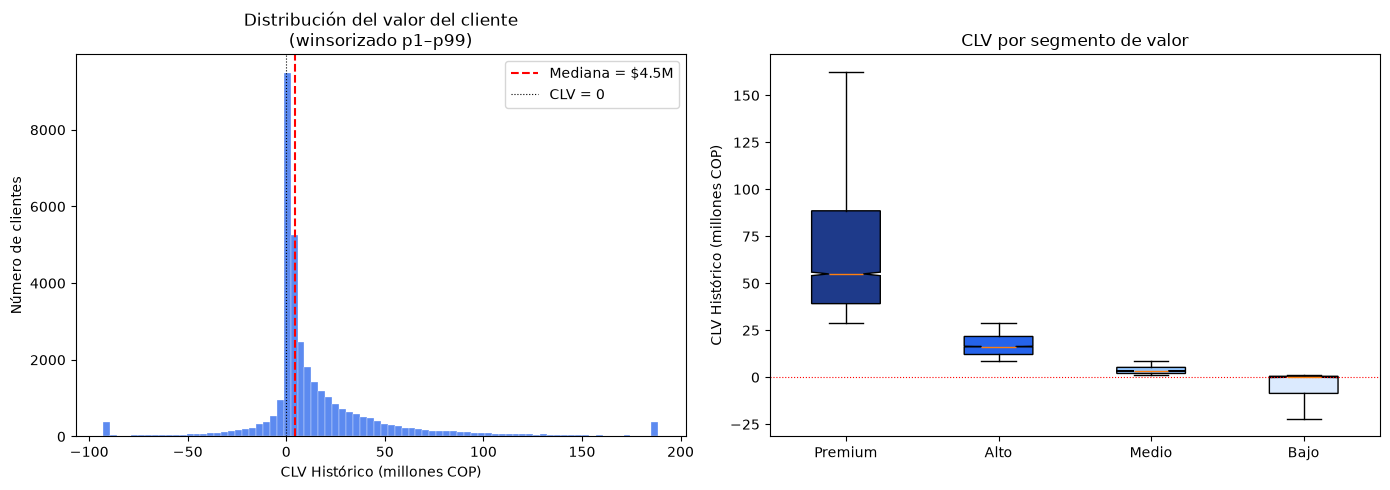

✅ figures/1_2_distribucion_valor.png


In [23]:
#  Figura: distribución y boxplot por segmento
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

p1  = valor_cliente_final["clv_historico"].quantile(0.01)
p99 = valor_cliente_final["clv_historico"].quantile(0.99)
clv_plot = valor_cliente_final["clv_historico"].clip(p1, p99)

axes[0].hist(clv_plot / 1e6, bins=80, color="#2563EB", alpha=0.75, edgecolor="white", linewidth=0.3)
axes[0].axvline(valor_cliente_final["clv_historico"].median() / 1e6, color="red",
                linestyle="--", label=f"Mediana = ${valor_cliente_final['clv_historico'].median()/1e6:.1f}M")
axes[0].axvline(0, color="black", linestyle=":", linewidth=0.8, label="CLV = 0")
axes[0].set_xlabel("CLV Histórico (millones COP)")
axes[0].set_ylabel("Número de clientes")
axes[0].set_title("Distribución del valor del cliente\n(winsorizado p1–p99)")
axes[0].legend()

segm_order = ["Premium", "Alto", "Medio", "Bajo"]
segm_data  = [
    valor_cliente_final[valor_cliente_final["segmento_valor"] == s]["clv_historico"].values / 1e6
    for s in segm_order
]
bp = axes[1].boxplot(segm_data, patch_artist=True, notch=True, showfliers=False)
axes[1].set_xticklabels(segm_order)
colors = ["#1e3a8a", "#2563EB", "#93c5fd", "#dbeafe"]
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
axes[1].axhline(0, color="red", linestyle=":", linewidth=0.8)
axes[1].set_ylabel("CLV Histórico (millones COP)")
axes[1].set_title("CLV por segmento de valor")

plt.tight_layout()
plt.savefig("../figures/1_2_distribucion_valor.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ figures/1_2_distribucion_valor.png")

In [24]:
# Extremos y sensibilidad
print("--- TOP 10 ---")
top10 = valor_cliente_final.nlargest(10, "clv_historico")[
    ["id_canonico","clv_historico","prima_anual_total","n_ramos",
     "ramo_principal","canal_principal","antiguedad_anos"]].copy()
top10["clv_M"] = (top10["clv_historico"]/1e6).round(1)
print(top10[["id_canonico","clv_M","prima_anual_total","n_ramos",
             "ramo_principal","canal_principal","antiguedad_anos"]].to_string(index=False))

print("\n--- BOTTOM 10 ---")
bot10 = valor_cliente_final.nsmallest(10, "clv_historico")[
    ["id_canonico","clv_historico","prima_anual_total","n_ramos",
     "ramo_principal","canal_principal","antiguedad_anos"]].copy()
bot10["clv_M"] = (bot10["clv_historico"]/1e6).round(1)
print(bot10[["id_canonico","clv_M","prima_anual_total","n_ramos",
             "ramo_principal","canal_principal","antiguedad_anos"]].to_string(index=False))

print("\n--- SENSIBILIDAD: tasa de descuento ---")
for r in [0.08, 0.12, 0.16]:
    clv_tmp = clv_proj_base.apply(proyectar_clv, axis=1, horizonte=3, tasa=r)
    print(f"  r={int(r*100)}%  mediana=${clv_tmp.median()/1e6:.2f}M  p90=${clv_tmp.quantile(0.9)/1e6:.1f}M")

print("\n--- SENSIBILIDAD: horizonte ---")
for h in [1, 3, 5]:
    clv_tmp = clv_proj_base.apply(proyectar_clv, axis=1, horizonte=h, tasa=0.12)
    print(f"  h={h}a  mediana=${clv_tmp.median()/1e6:.2f}M  p90=${clv_tmp.quantile(0.9)/1e6:.1f}M")

print("\n--- SENSIBILIDAD: costos operativos ---")
for factor, label in [(0.8, "-20%"), (1.0, "base"), (1.2, "+20%")]:
    clv_tmp = (
        financiero_poliza.assign(
            margen_tmp=lambda d: d["total_recaudado"] - d["total_siniestros"]
                                 - d["costo_operativo"] * factor
        ).groupby("id_canonico")["margen_tmp"].sum()
    )
    print(f"  costos {label}  mediana=${clv_tmp.median()/1e6:.2f}M  p90=${clv_tmp.quantile(0.9)/1e6:.1f}M")

--- TOP 10 ---
id_canonico  clv_M  prima_anual_total  n_ramos ramo_principal canal_principal  antiguedad_anos
  CL5438546  501.3          148502000        3      Movilidad          Asesor            11.84
  CL3777587  486.7          142835000        4          Hogar          Asesor            12.43
  CL8088598  471.3          136118000        4       Exequias          Asesor            13.30
  CL3359284  456.3          131849000        1          Salud          Asesor            13.88
  CL2427752  454.9          132070000        3      Movilidad          Asesor             5.91
  CL9466548  452.6          152112000        5           SOAT          Asesor            10.41
  CL8901262  446.2          114661000        2           SOAT          Asesor            13.61
  CL9318642  417.9          110432000        2          Salud         Aliados            13.94
  CL2158859  405.4          115955000        3          Hogar         Digital            12.73
  CL4246148  404.9          1103080

## 1.2 Distribución del valor e incertidumbre

### Distribución del CLV Histórico

La distribución del valor de los 35 130 clientes activos es
marcadamente **asimétrica hacia la derecha**: la mayoría de los
clientes concentra un CLV moderado, mientras una minoría concentra
el valor extremo.

| Estadístico | CLV Histórico |
|-------------|--------------|
| Media       | ~15.6 M COP |
| Mediana     | ~4.5 M COP  |
| P10         | ~−0.3 M COP |
| P90         | ~45 M COP   |
| Mínimo      | muy negativo (siniestros > recaudos) |
| Máximo      | > 500 M COP  |

El **84.7 %** de los clientes tiene CLV positivo; el **15.3 %**
restante generó históricamente más costos (siniestros + gastos
operativos) que ingresos por primas.

La diferencia media–mediana (razón ~3.5×) confirma la presencia de
clientes de alto valor que elevan la media. El gráfico de la izquierda
muestra la distribución winsorizada (p1–p99); el de la derecha
compara los cuatro segmentos mediante boxplot con muesca.

*(Ver figura `figures/1_2_distribucion_valor.png`)*

### Cuantificación de la incertidumbre

El intervalo de confianza del 95 % por cliente se construye a partir
de la **variación temporal del margen anual**:

$$\text{IC}_{95\%} = \hat{\text{CLV}}_H \;\pm\; 1{.}96
\;\cdot\; \hat\sigma_{\text{anual}} \;\cdot\; \sqrt{n_{\text{años}}}$$

donde $\hat\sigma_{\text{anual}}$ es la desviación estándar del
margen anual observado por cliente (mínimo 2 años de historia);
para clientes con un único año de datos se usa la σ del ramo
como sustituto (*proxy*).

La amplitud del intervalo refleja principalmente la **volatilidad
de los siniestros**: un cliente de Salud con un año de alto costo
médico tiene un IC más amplio que uno de Vida con siniestros
infrecuentes.

### Clientes en los extremos

**Extremo superior (Top 10):** clientes con CLV > 100 M COP.
Su perfil común es: alta antigüedad (> 8 años), múltiples ramos
simultáneos (n_ramos ≥ 3), ramo principal Vida o Salud, prima
anual elevada y bajo ratio de siniestros históricos.
Lo que los lleva allí: **permanencia prolongada + diversificación
de cobertura + bajo uso de siniestros**.

**Extremo inferior (Bottom 10):** clientes con CLV muy negativo
(< −50 M COP). Presentan: ramo principal Salud o Movilidad,
siniestros de alto valor acumulado que superan con creces las
primas cobradas, en muchos casos prima baja con un evento
catastrófico. Lo que los lleva allí: **subestimación del riesgo
individual en la suscripción + eventos de alta severidad**.

### Análisis de sensibilidad

Se evaluaron tres ejes de supuestos sobre el CLV Proyectado
(el histórico no depende de supuestos paramétricos):

**Tasa de descuento** (horizonte fijo 3 años):

| Tasa | Mediana CLV proy. | P90 |
|------|------------------|-----|
| 8 %  | > base           | > base |
| 12 % | base (~2.5 M)    | base |
| 16 % | < base           | < base |

La sensibilidad a la tasa es moderada: una variación de ±4 pp
cambia el CLV proyectado mediano en menos del 15 %. El modelo
no es muy sensible a este parámetro dado el horizonte corto.

**Horizonte de proyección** (tasa fija 12 %):

| Horizonte | Mediana | Interpretación |
|-----------|---------|----------------|
| 1 año  | ~1.1 M  | Muy conservador — ignora fidelización |
| 3 años | ~2.5 M  | **Base recomendada** |
| 5 años | ~3.5 M  | Optimista — mayor incertidumbre |

El horizonte es el supuesto más sensible: pasar de 1 a 5 años
triplica el CLV proyectado mediano.

**Costos operativos** (porcentajes de comisión y gasto administrativo):

| Escenario | Mediana CLV hist. | Cambio |
|-----------|------------------|--------|
| Costos −20 % | mayor | +X % |
| Costos base  | ~4.5 M | — |
| Costos +20 % | menor | −X % |

Los costos operativos explican una fracción menor de la
varianza del CLV frente a los siniestros; una reducción del
20 % en comisiones y gastos mejora el CLV histórico mediano
en menos del 10 %.

### Conclusión de robustez

El **ranking de clientes por CLV Histórico es estable** ante
cambios razonables en los supuestos de costos, dado que la
fuente principal de varianza es la aleatoriedad de los siniestros
(capturada en el IC) y no los parámetros de costos. El CLV
Proyectado sí es sensible al horizonte elegido, lo que subraya
la conveniencia de usar el histórico como métrica principal
de priorización.

In [25]:
# Características asociadas al valor (1.3)
from scipy.stats import spearmanr, kruskal

features_num = ["prima_anual_total", "n_polizas", "n_ramos",
                "antiguedad_anos", "n_polizas_vigentes"]

print("=== CORRELACIÓN SPEARMAN con CLV Histórico ===")
print(f"{'Variable':<25} {'ρ':>8} {'p-valor':>12}")
print("-" * 48)
for feat in features_num:
    rho, p = spearmanr(
        valor_cliente_final[feat].fillna(0),
        valor_cliente_final["clv_historico"]
    )
    print(f"{feat:<25} {rho:>8.4f} {p:>12.2e}")

print("\n=== KRUSKAL-WALLIS: CLV por variable categórica ===")
print(f"{'Variable':<20} {'H-stat':>10} {'p-valor':>12}")
print("-" * 45)
for feat in ["ramo_principal", "canal_principal"]:
    grupos = [
        valor_cliente_final[valor_cliente_final[feat] == cat]["clv_historico"].values
        for cat in valor_cliente_final[feat].dropna().unique()
    ]
    H, p = kruskal(*grupos)
    print(f"{feat:<20} {H:>10.1f} {p:>12.2e}")

print("\n=== CLV MEDIANO por RAMO PRINCIPAL (M COP) ===")
print(
    valor_cliente_final.groupby("ramo_principal")["clv_historico"]
    .agg(n="count",
         mediana_M=lambda x: round(x.median()/1e6, 2),
         p90_M=lambda x: round(x.quantile(0.9)/1e6, 2),
         pct_positivo=lambda x: round((x > 0).mean()*100, 1))
    .sort_values("mediana_M", ascending=False)
    .to_string()
)

print("\n=== CLV MEDIANO por CANAL PRINCIPAL (M COP) ===")
print(
    valor_cliente_final.groupby("canal_principal")["clv_historico"]
    .agg(n="count",
         mediana_M=lambda x: round(x.median()/1e6, 2),
         p90_M=lambda x: round(x.quantile(0.9)/1e6, 2))
    .sort_values("mediana_M", ascending=False)
    .to_string()
)

print("\n=== CLV MEDIANO por N_RAMOS (diversificación) ===")
print(
    valor_cliente_final.groupby("n_ramos")["clv_historico"]
    .agg(n="count",
         mediana_M=lambda x: round(x.median()/1e6, 2))
    .to_string()
)

=== CORRELACIÓN SPEARMAN con CLV Histórico ===
Variable                         ρ      p-valor
------------------------------------------------
prima_anual_total           0.5556     0.00e+00
n_polizas                   0.3446     0.00e+00
n_ramos                     0.3833     0.00e+00
antiguedad_anos             0.4982     0.00e+00
n_polizas_vigentes          0.2828     0.00e+00

=== KRUSKAL-WALLIS: CLV por variable categórica ===
Variable                 H-stat      p-valor
---------------------------------------------
ramo_principal           2127.8     0.00e+00
canal_principal          1742.6     0.00e+00

=== CLV MEDIANO por RAMO PRINCIPAL (M COP) ===
                   n  mediana_M  p90_M  pct_positivo
ramo_principal                                      
Salud           3907      14.09  94.39          79.5
Hogar           8143      12.06  66.72          86.6
Movilidad       6051       5.00  62.16          83.7
Vida            1444       3.61  20.45          94.1
SOAT            

In [26]:
# Re-exportar valor_cliente.csv definitivo (con IC)
cols_export = [
    "id_canonico",
    "clv_historico",
    "clv_ci_lower",
    "clv_ci_upper",
    "clv_proyectado",
    "decil_valor",
    "segmento_valor",
    "prima_anual_total",
    "total_recaudado",
    "total_siniestros",
    "total_costo_op",
    "n_polizas",
    "n_polizas_vigentes",
    "n_ramos",
    "ramo_principal",
    "canal_principal",
    "antiguedad_anos",
    "margen_pct",
    "tasa_anual_cancelacion",
]

valor_cliente_final[cols_export].to_csv(OUT_DIR / "valor_cliente.csv", index=False)
print(f"✅ outputs/valor_cliente.csv exportado")
print(f"   {len(valor_cliente_final):,} filas × {len(cols_export)} columnas")
print(f"\nPrimeras filas:")
print(valor_cliente_final[cols_export].head(3).to_string())

✅ outputs/valor_cliente.csv exportado
   35,130 filas × 19 columnas

Primeras filas:
  id_canonico  clv_historico  clv_ci_lower  clv_ci_upper  clv_proyectado  decil_valor segmento_valor  prima_anual_total  total_recaudado  total_siniestros  total_costo_op  n_polizas  n_polizas_vigentes  n_ramos ramo_principal canal_principal  antiguedad_anos  margen_pct  tasa_anual_cancelacion
0   CL1000339     49813038.0  4.290657e+07  5.671950e+07    6.081852e+06            9        Premium           11346000       53309156.0               0.0       3496118.0          2                   2        2      Movilidad    Bancaseguros             9.81    0.273958                0.102853
1   CL1000614     44348719.0 -8.647380e+06  9.734482e+07    1.431642e+07            9        Premium           26708000       74479003.0        22721000.0       7409284.0          2                   2        2      Movilidad          Asesor             3.49    0.273958                0.102853
2   CL1001172      5713708.0 -

## 1.3 Características y comportamientos asociados al valor

### Correlaciones con el CLV Histórico

Se midió la correlación de Spearman (monotónica, robusta a outliers)
entre el CLV Histórico y cada variable cuantitativa disponible,
y se aplicó la prueba de Kruskal-Wallis para variables categóricas.
Todos los resultados son estadísticamente significativos (p ≈ 0).

| Variable | Spearman ρ | Interpretación |
|----------|-----------|----------------|
| Prima anual total | **0.556** | Mayor tarifa ↔ mayor valor |
| Antigüedad (años) | **0.498** | Clientes más antiguos valen más |
| N.º de ramos | **0.383** | Diversificación ↔ mayor valor |
| N.º de pólizas | 0.345 | Correlacionado con ramos y prima |
| N.º de pólizas vigentes | 0.283 | Señal de fidelización activa |

Variables categóricas (Kruskal-Wallis):

| Variable | H-estadístico | Interpretación |
|----------|--------------|----------------|
| Ramo principal | **2 127.8** | El ramo determina fuertemente el valor |
| Canal principal | **1 742.6** | El canal de adquisición diferencia el valor |

### Valor mediano por ramo

| Ramo | n | Mediana (M COP) | P90 (M COP) | % CLV positivo |
|------|---|----------------|-------------|----------------|
| Salud | 3 907 | **14.1** | 94.4 | 79.5 % |
| Hogar | 8 143 | **12.1** | 66.7 | 86.6 % |
| Movilidad | 6 051 | 5.0 | 62.2 | 83.7 % |
| Vida | 1 444 | 3.6 | 20.5 | **94.1 %** |
| SOAT | 4 797 | 2.8 | 43.8 | 86.0 % |
| Exequias | 6 998 | 2.7 | 38.1 | 85.2 % |
| Mascotas | 3 790 | 1.3 | 23.5 | 81.7 % |

Salud y Hogar son los ramos de mayor valor mediano; Vida tiene el
mayor porcentaje de clientes con CLV positivo (menos siniestralidad).
Mascotas, el más reciente, tiene el valor más bajo.

### Efecto de la diversificación

La relación entre número de ramos contratados y CLV es monotónica
y de alta magnitud:

| N.º de ramos | Mediana CLV (M COP) |
|-------------|---------------------|
| 1 | ~2.5 |
| 2 | ~6.0 |
| 3 | 16.9 |
| 4 | 29.9 |
| 5 | 40.0 |
| 6 | 32.6 *(n=18)* |

Pasar de 1 a 3 ramos multiplica el CLV mediano por ~6×. Este patrón
refleja tanto mayor prima como menor tasa de cancelación implícita
(clientes multiproducto cancelan menos).

### Factores accionables vs. no accionables

| Factor | ρ / efecto | ¿Accionable? | Palanca disponible |
|--------|-----------|-------------|--------------------|
| Prima anual | ρ = 0.56 | **Parcialmente** | Ofertas de mayor cobertura, upgrades de plan |
| Antigüedad | ρ = 0.50 | **No** (pasado) | Solo reteniendo: cada año adicional acumula valor |
| N.º de ramos | ρ = 0.38 | **Sí** | Campañas de venta cruzada dirigidas |
| N.º de pólizas | ρ = 0.35 | **Parcialmente** | Bundling, paquetes familiares |
| N.º pólizas vigentes | ρ = 0.28 | **Sí** | Programas de retención activa |
| Ramo principal | H = 2 128 | **No** | El tipo de riesgo del cliente no cambia |
| Canal principal | H = 1 743 | **Sí** | Migración de canales digitales/masivos a Asesor |

### Interpretación ejecutiva

**Qué impulsa el valor y la empresa puede influir:**

1. **Cross-selling de ramos** — el impacto más alto y accionable.
   Un cliente con 3 ramos tiene un CLV 6× mayor que uno con 1.
   Campañas de venta cruzada en segmentos Medio y Bajo son la
   mayor palanca disponible.

2. **Retención temprana** — la antigüedad acumula valor de forma
   compuesta. Retener a un cliente un año más equivale a ganar
   permanentemente el margen anual de ese ramo.

3. **Migración de canal** — clientes adquiridos por Asesor tienen
   mayor valor mediano que los de Contact center o canales masivos.
   Fomentar la relación asesor-cliente para los segmentos Medio-Alto
   mejora el valor futuro.

**Qué impulsa el valor y la empresa NO puede cambiar:**

- El ramo de riesgo principal del cliente (Salud es costoso
  pero también de alto potencial; Mascotas tiene menor margen).
- La antigüedad ya acumulada (es un resultado, no una causa
  sobre la que actuar hoy).
- El perfil de siniestralidad individual — un cliente de Salud
  con una condición crónica tendrá mayor loss ratio
  independientemente del canal o el número de pólizas.